# Hospital Readmission: Data Cleaning and Preprocessing (condensed)

**COMP 9170 group project** · UCI Diabetes 130-US Hospitals (1999 to 2008) · Author: Jason Fakidis (`jason-dev`)

Turns 101,766 raw hospital stays into clean, model-ready train and test sets for predicting **readmission within 30 days**. Full detail is in `01_data_cleaning_preprocessing.ipynb`.

Ground rules: seed 42 everywhere; the raw data is never changed; every row removal is logged; anything learned from the data is learned from the training set only.

## 0. Setup
**Decisions:** a fixed seed (42) so every run gives the same result; relative paths; the raw CSVs are extracted from the committed zip if they're missing, so the notebook runs from a fresh clone.

In [1]:
import sys, csv, zipfile
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split

SEED = 42; ALPHA = 0.05
DATA_DIR = Path("../data"); OUT_DIR = DATA_DIR / "processed"; RESULTS_DIR = Path("../results")
OUT_DIR.mkdir(parents=True, exist_ok=True); RESULTS_DIR.mkdir(parents=True, exist_ok=True)
RAW_CSV, IDS_CSV = DATA_DIR / "diabetic_data.csv", DATA_DIR / "IDS_mapping.csv"
if not RAW_CSV.exists():
    with zipfile.ZipFile(DATA_DIR / "diabetes+130-us+hospitals+for+years+1999-2008.zip") as z:
        z.extractall(DATA_DIR)
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200)

## 1. Load
**Decisions**
- Read every value as plain text first, to see which strings really mean "missing" instead of trusting pandas' defaults.
- Treat three strings as missing: `?`, `Unknown/Invalid` and `PhysicianNotFound`.
- Keep `"None"` as a real value. In the two lab-test columns it means the test wasn't ordered, which is information. `keep_default_na=False` stops pandas from turning it into a blank.

**Results**
- `?` appears in 7 columns, most heavily `weight`, `medical_specialty` and `payer_code`. `Unknown/Invalid` is 3 gender values; `PhysicianNotFound` is 11 specialty values.
- 101,766 rows by 50 columns. About 181,000 `"None"` lab values survive the load (checked by an assert).

In [2]:
raw_text = pd.read_csv(RAW_CSV, dtype=str, keep_default_na=False)
CONFIRMED_MARKERS = ["?", "Unknown/Invalid", "PhysicianNotFound"]
print("Marker counts:\n", pd.DataFrame({m: (raw_text == m).sum() for m in CONFIRMED_MARKERS})
      .pipe(lambda d: d[d.sum(axis=1) > 0]).to_string())

raw = pd.read_csv(RAW_CSV, na_values=CONFIRMED_MARKERS, keep_default_na=False, low_memory=False)
df = raw.copy(); RAW_SHAPE = raw.shape
assert (df["A1Cresult"] == "None").sum() == (raw_text["A1Cresult"] == "None").sum()  # "None" preserved
print("Raw shape:", RAW_SHAPE)

Marker counts:
                        ?  Unknown/Invalid  PhysicianNotFound
race                2273                0                  0
gender                 0                3                  0
weight             98569                0                  0
payer_code         40256                0                  0
medical_specialty  49949                0                 11
diag_1                21                0                  0
diag_2               358                0                  0
diag_3              1423                0                  0


Raw shape: (101766, 50)


## 2. Validation
**Decisions**
- Check the data against its documentation before changing anything. Any failure stops the notebook.
- Checks: no duplicate rows or stay IDs; every admission, discharge and source code exists in `IDS_mapping.csv`; stays are 1 to 14 days (the dataset's own inclusion rule); counts are never negative.
- Flag columns that have the same value in every row.

**Results**
- Every check passes.
- 71,518 patients, but 23.5% of them have more than one stay, and those stays make up 46.2% of the rows. This drives the de-duplication in Section 3.
- `examide` and `citoglipton` have one value everywhere, so they carry no information.

In [3]:
assert df.duplicated().sum() == 0 and df["encounter_id"].duplicated().sum() == 0
reps = df.groupby("patient_nbr").size()
print(f"{reps.size:,} patients; {(reps>1).mean()*100:.1f}% have >1 encounter ({reps[reps>1].sum()/len(df)*100:.1f}% of rows)")

def load_id_mappings(path):
    maps, cur = {}, None
    for row in csv.reader(open(path, newline="", encoding="utf-8")):
        if not row or all(c.strip() == "" for c in row): cur = None; continue
        k, d = row[0].strip(), row[1].strip()
        if cur is None: cur = k; maps[cur] = {}; continue
        maps[cur][int(k)] = d
    return maps
ID_MAPS = load_id_mappings(IDS_CSV)
for col, m in ID_MAPS.items():
    assert not (set(df[col].unique()) - set(m)), f"unmapped code in {col}"

first_med, last_med = df.columns.get_loc("metformin"), df.columns.get_loc("metformin-pioglitazone")
MED_COLS = list(df.columns[first_med:last_med + 1])
NUMERIC_COLS = ["time_in_hospital","num_lab_procedures","num_procedures","num_medications",
                "number_outpatient","number_emergency","number_inpatient","number_diagnoses"]
numeric_rules = {"time_in_hospital": (1, 14), "number_diagnoses": (1, None)}  # others: >=0
for c in NUMERIC_COLS:
    lo, hi = numeric_rules.get(c, (0, None))
    assert (df[c] >= lo).all() and (hi is None or (df[c] <= hi).all()), f"range violation {c}"
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print("All ID codes mapped, numeric ranges OK. Constant columns:", constant_cols)

71,518 patients; 23.5% have >1 encounter (46.2% of rows)
All ID codes mapped, numeric ranges OK. Constant columns: ['examide', 'citoglipton']


## 3. Row cleaning
**Decisions**
1. **Drop the 3 rows with missing or invalid gender.** They can't be recovered.
2. **Keep only each patient's first stay.** Several stays from one person aren't independent, and a patient in both train and test would inflate test scores. The cost is that later stays are removed along with their readmission labels. "First" assumes a lower stay ID means an earlier stay, which isn't verified.
3. **Drop stays that ended in death or hospice.** Patients who died can never be readmitted (none of the 1,652 were). Hospice patients rarely return, are in end-of-life care, and often die after discharge without it being recorded, so their labels are unreliable. Dropping both follows Strack et al. (2014).

**Results**
- 101,766 rows, then 101,763 after the gender step, 71,515 after keeping first stays, and **69,970 patients** after removing death and hospice (68.8% of the raw rows).
- Each patient now appears exactly once.

In [4]:
log = [("raw", len(df))]
df = df.loc[df["gender"].notna()];                                        log.append(("drop missing/invalid gender", len(df)))
df = df.sort_values("encounter_id").drop_duplicates("patient_nbr", keep="first");      log.append(("first encounter/patient", len(df)))
df = df.loc[~df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])];           log.append(("drop expired/hospice", len(df)))
df = df.reset_index(drop=True)
cleaning_log_df = pd.DataFrame(log, columns=["step", "rows_after"]).assign(
    pct_remaining=lambda d: (100 * d["rows_after"] / log[0][1]).round(1))
assert df["patient_nbr"].is_unique and raw.shape == RAW_SHAPE
print(cleaning_log_df.to_string(index=False))

                       step  rows_after  pct_remaining
                        raw      101766          100.0
drop missing/invalid gender      101763          100.0
    first encounter/patient       71515           70.3
       drop expired/hospice       69970           68.8


## 4. Target: 30-day readmission
**Decisions**
- Positive (1) means readmitted within 30 days. Readmitted after 30 days, or not at all, is 0. This is the clinical standard and matches Strack et al.
- The original 3-level `readmitted` column is never used as a feature, because it is the answer.

**Results**
- **8.97%** of patients are positive (6,277 of 69,970).
- Always predicting "not readmitted" would be 91.0% accurate while catching nobody, so accuracy is a poor measure here. Use PR-AUC, recall, F1, ROC-AUC and calibration, compared against that baseline.
- Caveat: the 22,222 patients readmitted after 30 days count as negatives but look much like the positives (similar prior visits and number of diagnoses). The data has no dates, so patients who came back soon after day 30 can't be separated out. Some "false positives" will really be later readmissions.

Prevalence: 0.0897 (6277/69970); majority-class accuracy = 0.9103


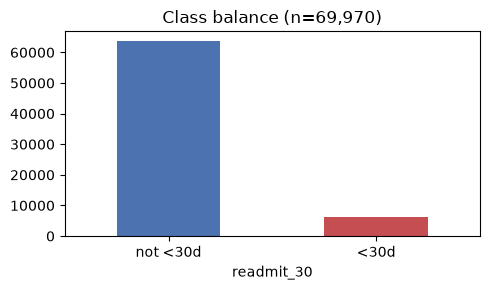

In [5]:
# 30-day readmission: "<30" = 1; ">30" and "NO" = 0.
df["readmit_30"] = (df["readmitted"] == "<30").astype(int)
prev = df["readmit_30"].mean()
print(f"Prevalence: {prev:.4f} ({df['readmit_30'].sum()}/{len(df)}); majority-class accuracy = {max(prev, 1-prev):.4f}")

fig, ax = plt.subplots(figsize=(5, 3))
df["readmit_30"].value_counts().sort_index().plot.bar(ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title(f"Class balance (n={len(df):,})"); ax.set_xticklabels(["not <30d", "<30d"], rotation=0); plt.tight_layout(); plt.show()

## 5. Missing values
**Decisions**
- Don't drop rows or fill in the most common value. Whether a value is missing is related to readmission (for example, 9.9% readmitted when `payer_code` is missing vs 8.3% when it's recorded), so the gap itself is information.
- `weight` (96% missing): drop it and keep a 0/1 `weight_recorded` flag.
- `medical_specialty`, `payer_code`, `race`: give missing values their own level, `"Unknown"`.
- Lab `"None"`: rename to `"Not measured"`.
- Missing diagnoses: handled in Section 7 as a `"Missing"` group.
- Drop the two constant columns.

**Results**
- Missing before treatment: `weight` 96.0%, `medical_specialty` 48.1%, `payer_code` 43.5%, `race` 2.7%, diagnoses under 2%.
- No numeric column had gaps, so nothing was imputed. Only the diagnosis columns still have blanks (10, 293 and 1,224), which Section 7 handles.

In [6]:
print((100 * df.isna().mean()).round(2)[lambda s: s > 0].sort_values(ascending=False).to_string())
df["weight_recorded"] = df["weight"].notna().astype(int)
df = df.drop(columns=["weight"] + constant_cols)
MED_COLS = [m for m in MED_COLS if m not in constant_cols]
for c in ["medical_specialty", "payer_code", "race"]:
    df[c] = df[c].fillna("Unknown")
for c in ["max_glu_serum", "A1Cresult"]:
    df[c] = df[c].replace({"None": "Not measured"})
print("Remaining NaN (diagnoses, fixed in §7):", df.isna().sum()[lambda s: s > 0].to_dict())

weight               96.02
medical_specialty    48.08
payer_code           43.47
race                  2.74
diag_3                1.75
diag_2                0.42
diag_1                0.01
Remaining NaN (diagnoses, fixed in §7): {'diag_1': 10, 'diag_2': 293, 'diag_3': 1224}


## 6. Outliers
**Decisions**
- Check all 8 numeric variables, not just one (course convention), using the 1.5 × IQR rule, |z| > 3, skewness and histograms.
- Treat a flag as something to investigate, not as an error.
- Remove nothing. Add log versions (`log1p`) of the skewed visit counts instead.

**Results**
- Every flagged value is plausible: long stays at the 14-day cap, patients on many medications, frequent users of care.
- For the three prior-visit counts most patients have zero, so the IQR rule flags every non-zero value. Skewness is the better guide there.
- The frequent users are kept on purpose, because prior visits are the strongest readmission signal.
- The log versions cut skew sharply: emergency visits from 21.2 to 4.3, total visits from 6.7 to 1.9.

                    min  max  iqr_flag%   z>3   skew
var                                                 
time_in_hospital      1   14       2.01   642   1.18
num_lab_procedures    1  132       0.14    31  -0.22
num_procedures        0    6       5.50     0   1.23
num_medications       1   81       2.67  1041   1.43
number_outpatient     0   42      13.03  1263   9.70
number_emergency      0   42       7.29  1218  21.23
number_inpatient      0   12      11.71  2397   5.59
number_diagnoses      1   16       0.34   235  -0.72


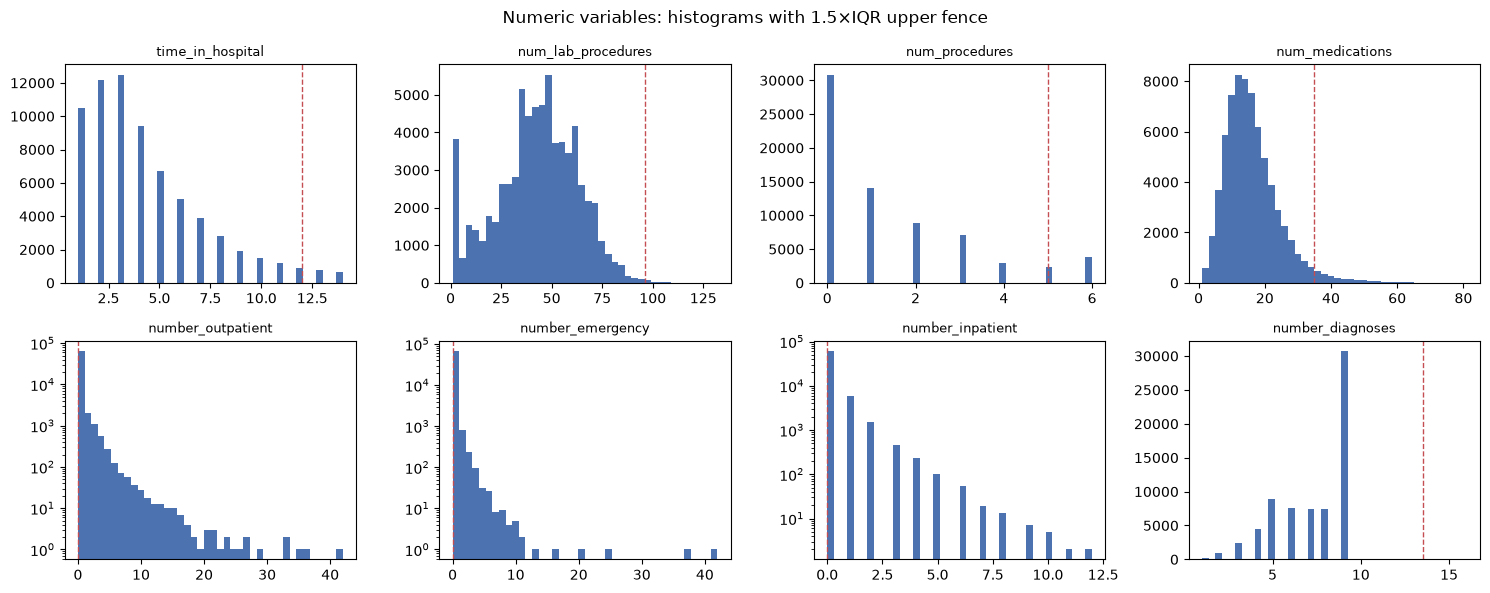

skew after log1p: {'number_outpatient': np.float64(3.15), 'number_emergency': np.float64(4.26), 'number_inpatient': np.float64(3.13), 'total_visits': np.float64(1.91)}


In [7]:
def iqr_fences(s, k=1.5):
    q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for c in NUMERIC_COLS:
    s = df[c]; lo, hi = iqr_fences(s); z = (s - s.mean()) / s.std(ddof=0)
    rows.append({"var": c, "min": s.min(), "max": s.max(), "iqr_flag%": round(100*((s<lo)|(s>hi)).mean(), 2),
                 "z>3": int((z.abs()>3).sum()), "skew": round(stats.skew(s), 2)})
print(pd.DataFrame(rows).set_index("var").to_string())

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axes.ravel(), NUMERIC_COLS):
    ax.hist(df[c], bins=40, color="#4C72B0"); ax.axvline(iqr_fences(df[c])[1], color="#C44E52", ls="--", lw=1)
    if stats.skew(df[c]) > 3: ax.set_yscale("log")
    ax.set_title(c, fontsize=9)
fig.suptitle("Numeric variables: histograms with 1.5×IQR upper fence"); plt.tight_layout(); plt.show()

UTIL = ["number_outpatient", "number_emergency", "number_inpatient"]
df["total_visits"] = df[UTIL].sum(axis=1)
LOG_COLS = UTIL + ["total_visits"]
for c in LOG_COLS: df[f"log1p_{c}"] = np.log1p(df[c])
print("skew after log1p:", {c: round(stats.skew(df[f'log1p_{c}']), 2) for c in LOG_COLS})

## 7. Feature engineering
**Decisions**
- Use only fixed rules (nothing learned from the data), so these steps are safe before the train/test split.
- Age bracket becomes its midpoint (`[70-80)` becomes 75), keeping the order in one column.
- Admission type, discharge destination and admission source codes become a few groups each, merging the various "unknown" codes.
- The 700+ diagnosis codes per column become 9 disease groups plus "Missing", following Strack et al.
- Medications become two counts: drugs the patient is on, and drugs whose dose changed. Gender, medication change and diabetes medication become 0/1 flags.

**Results**
- Each code column shrinks to 5 or 6 groups, and each diagnosis column to 10.
- Circulatory disease is the most common primary diagnosis (21,383 patients).
- Every code maps to a group (checked by asserts).

In [8]:
df["age_mid"] = df["age"].str.extract(r"\[(\d+)-")[0].astype(int) + 5

ADM_T = {1:"Emergency",2:"Urgent",3:"Elective",4:"Other",7:"Other",5:"Unknown",6:"Unknown",8:"Unknown"}
DISCH = {1:"Home",6:"Home with care",8:"Home with care",7:"Left AMA",
         **{c:"Transferred" for c in [2,3,4,5,10,15,16,17,22,23,24,27,28,29,30]},
         9:"Other",12:"Other",18:"Unknown",25:"Unknown",26:"Unknown"}
ADM_S = {**{c:"Referral" for c in [1,2,3]}, 7:"Emergency room",
         **{c:"Transfer" for c in [4,5,6,10,18,19,22,25,26]},
         **{c:"Other" for c in [8,11,12,13,14,23,24]}, **{c:"Unknown" for c in [9,15,17,20,21]}}
for src, dst, m in [("admission_type_id","admission_type",ADM_T),
                    ("discharge_disposition_id","discharge_group",DISCH),
                    ("admission_source_id","admission_source_group",ADM_S)]:
    df[dst] = df[src].map(m); assert df[dst].notna().all()

def icd9_group(code):
    if pd.isna(code): return "Missing"
    code = str(code)
    if code[0] in "VE": return "Other"
    v = float(code)
    if 250 <= v < 251: return "Diabetes"
    if 390 <= v < 460 or int(v)==785: return "Circulatory"
    if 460 <= v < 520 or int(v)==786: return "Respiratory"
    if 520 <= v < 580 or int(v)==787: return "Digestive"
    if 800 <= v < 1000: return "Injury"
    if 710 <= v < 740: return "Musculoskeletal"
    if 580 <= v < 630 or int(v)==788: return "Genitourinary"
    if 140 <= v < 240: return "Neoplasms"
    return "Other"
for i in (1, 2, 3): df[f"diag_{i}_group"] = df[f"diag_{i}"].map(icd9_group)

df["n_meds_on"]     = (df[MED_COLS] != "No").sum(axis=1)
df["n_med_changes"] = df[MED_COLS].isin(["Up", "Down"]).sum(axis=1)
df["gender_male"]   = (df["gender"] == "Male").astype(int)
df["med_change"]    = (df["change"] == "Ch").astype(int)
df["diabetes_med"]  = (df["diabetesMed"] == "Yes").astype(int)
print("Primary diagnosis groups:", df["diag_1_group"].value_counts().to_dict())

Primary diagnosis groups: {'Circulatory': 21383, 'Other': 12122, 'Respiratory': 9486, 'Digestive': 6487, 'Diabetes': 5748, 'Injury': 4692, 'Musculoskeletal': 4064, 'Genitourinary': 3440, 'Neoplasms': 2538, 'Missing': 10}


## 8. Train/test split
**Decisions**
- Split now, before anything is learned from the data (rare-level merging, correlations, tests), so the test set stays untouched.
- 80% train, 20% test, seed 42.
- Stratify on the target so both sets have the same readmission rate.

**Results**
- Train: 55,976 patients (5,022 readmitted). Test: 13,994 (1,255 readmitted). Both at 8.97%.
- No patient is in both sets (checked).
- Limitation: a random split tests new patients from the same hospitals and years, not future years or new hospitals.

In [9]:
NUMERIC_FEATURES = NUMERIC_COLS + ["total_visits"] + [f"log1p_{c}" for c in LOG_COLS] + \
    ["age_mid","n_meds_on","n_med_changes","gender_male","med_change","diabetes_med","weight_recorded"]
NOMINAL_FEATURES = ["race","admission_type","discharge_group","admission_source_group","payer_code",
    "medical_specialty","diag_1_group","diag_2_group","diag_3_group","max_glu_serum","A1Cresult"] + MED_COLS
TARGET = "readmit_30"

model_df = df[["encounter_id","patient_nbr"] + NUMERIC_FEATURES + NOMINAL_FEATURES + [TARGET]].copy()
train_df, test_df = train_test_split(model_df, test_size=.20, random_state=SEED, stratify=model_df[TARGET])
train_df, test_df = train_df.copy(), test_df.copy()
assert set(train_df["patient_nbr"]).isdisjoint(test_df["patient_nbr"])
print(f"train {len(train_df):,} (prev {train_df[TARGET].mean():.4f}) | test {len(test_df):,} (prev {test_df[TARGET].mean():.4f})")

train 55,976 (prev 0.0897) | test 13,994 (prev 0.0897)


## 9. Correlation (training set)
**Decisions**
- Spearman instead of Pearson, because most counts are skewed and some features are ordered categories. Spearman works on ranks, so extreme values don't dominate.

**Results**
- Every variable is only weakly related to readmission. The strongest are prior inpatient stays (0.085), total prior visits (0.066), length of stay (0.063) and age (0.049).
- No single feature predicts readmission, so a model has to combine many weak signals.
- Some features overlap heavily (for example `diabetes_med` and `n_meds_on`, 0.78). Linear models shouldn't use both.
- Correlation isn't causation: prior visits most likely reflect how sick the patient is.

Spearman rho with target (top):
number_inpatient      0.085
total_visits          0.066
time_in_hospital      0.063
age_mid               0.049
num_medications       0.043
number_diagnoses      0.043
num_lab_procedures    0.032
number_emergency      0.032
diabetes_med          0.027
n_med_changes         0.025
n_meds_on             0.017
number_outpatient     0.017
num_procedures        0.006


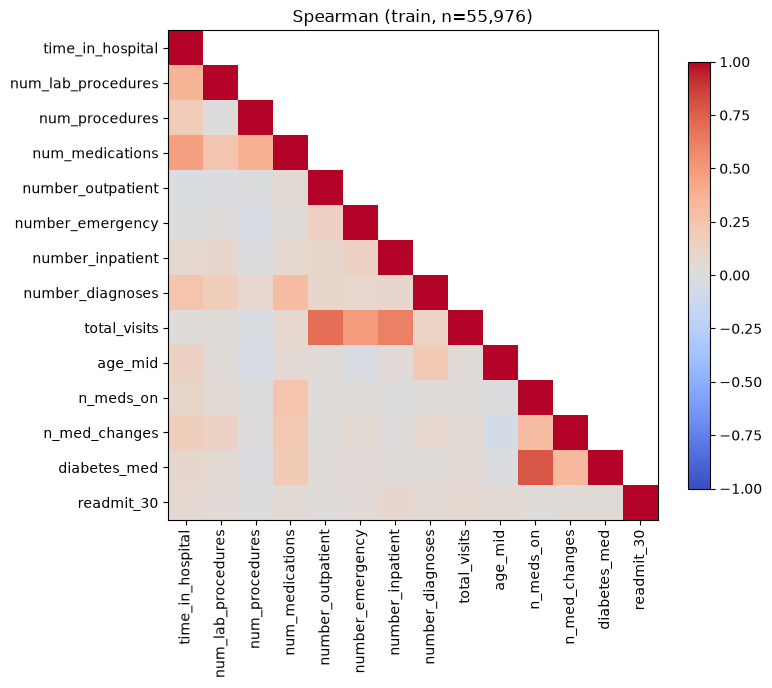

In [10]:
CORR_COLS = NUMERIC_COLS + ["total_visits","age_mid","n_meds_on","n_med_changes","diabetes_med", TARGET]
corr = train_df[CORR_COLS].corr(method="spearman")
print("Spearman rho with target (top):")
print(corr[TARGET].drop(TARGET).reindex(corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).index).round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.mask(np.triu(np.ones_like(corr, bool), 1)), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(CORR_COLS)), CORR_COLS, rotation=90); ax.set_yticks(range(len(CORR_COLS)), CORR_COLS)
fig.colorbar(im, shrink=.8); ax.set_title(f"Spearman (train, n={len(train_df):,})"); plt.tight_layout(); plt.show()

## 10. Significance tests (training set)
**Decisions**
- Compare readmitted and non-readmitted patients on 5 variables.
- Welch t-test (the groups differ in size and spread), KS test (whole distribution), and Cohen's d (size of the difference).
- Bonferroni correction for testing 5 variables: significant only if both p-values are below 0.05 / 5 = 0.01.

**Results**
- All 5 differences are significant, with p-values as small as 1e-48.
- That mostly reflects the large sample. The effect sizes are small: prior inpatient stays d = 0.35, length of stay 0.20, number of diagnoses 0.16, medications 0.13, lab procedures 0.11.
- The differences are real but modest, which again points to combining variables in a model.

In [11]:
def cohen_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na-1)*a.var(ddof=1) + (nb-1)*b.var(ddof=1)) / (na+nb-2))
    return (a.mean() - b.mean()) / sp

TEST_VARS = ["number_inpatient","time_in_hospital","num_medications","number_diagnoses","num_lab_procedures"]
alpha_b = ALPHA / len(TEST_VARS); lab = train_df[TARGET].to_numpy() == 1
rows = []
for c in TEST_VARS:
    x = train_df[c].to_numpy(float); a, b = x[lab], x[~lab]
    t, p = stats.ttest_ind(a, b, equal_var=False); ks = stats.ks_2samp(a, b)
    rows.append({"var": c, "diff": round(a.mean()-b.mean(), 3), "cohen_d": round(cohen_d(a, b), 3),
                 "p_welch": f"{p:.2e}", "sig_bonf": bool(max(p, ks.pvalue) < alpha_b)})
print(f"Bonferroni alpha = {alpha_b:.4f}\n", pd.DataFrame(rows).set_index("var").to_string())

Bonferroni alpha = 0.0100
                      diff  cohen_d   p_welch  sig_bonf
var                                                   
number_inpatient    0.209    0.347  1.15e-48      True
time_in_hospital    0.597    0.204  1.15e-39      True
num_medications     1.058    0.127  1.04e-17      True
number_diagnoses    0.318    0.159  2.07e-30      True
num_lab_procedures  2.217    0.111  1.82e-14      True


## 11. Encoding (rules learned from the training set)
**Decisions**
- Merge specialty and payer levels with under 1% of training patients into `"Rare"`, so the model doesn't get columns it can't learn from.
- Drop drugs taken by under 1% of training patients as separate columns. The medication counts still capture them.
- One-hot encode the categories (one 0/1 column per level), then give the test set exactly the training columns.
- Don't scale here. Trees don't need it; for other models, scaling goes in the modeling pipeline, fit on training data.

**Results**
- Specialty: 70 levels become 10 plus `Rare`. Payer: 18 become 9 plus `Rare`.
- 8 drugs kept, 13 dropped.
- 133 feature columns, identical in train and test.

In [12]:
RARE = 0.01
for c in ["medical_specialty", "payer_code"]:
    keep = set(train_df[c].value_counts(normalize=True)[lambda s: s >= RARE].index)
    for part in (train_df, test_df): part[c] = part[c].where(part[c].isin(keep), "Rare")
med_share = (train_df[MED_COLS] != "No").mean()
MEDS_DROP = sorted(med_share[med_share < RARE].index)

NOMINAL_FINAL = [c for c in NOMINAL_FEATURES if c not in MEDS_DROP]
FEATS = NUMERIC_FEATURES + NOMINAL_FINAL
X_train = pd.get_dummies(train_df[FEATS], columns=NOMINAL_FINAL, dtype=int)
X_test  = pd.get_dummies(test_df[FEATS],  columns=NOMINAL_FINAL, dtype=int).reindex(columns=X_train.columns, fill_value=0)
y_train, y_test = train_df[TARGET].to_numpy(), test_df[TARGET].to_numpy()
print(f"dropped rare meds: {MEDS_DROP}\nX_train {X_train.shape} | X_test {X_test.shape}")

dropped rare meds: ['acarbose', 'acetohexamide', 'chlorpropamide', 'glimepiride-pioglitazone', 'glipizide-metformin', 'glyburide-metformin', 'metformin-pioglitazone', 'metformin-rosiglitazone', 'miglitol', 'nateglinide', 'tolazamide', 'tolbutamide', 'troglitazone']
X_train (55976, 133) | X_test (13994, 133)


## 12. Export and final checks
**Decisions**
- Before writing files, confirm: raw data unchanged, no blanks, identical train and test columns, no ID or label columns among the features, no patient in both sets.

**Results**
- All checks pass.
- Files: `data/processed/train_clean.csv` (55,976 rows) and `test_clean.csv` (13,994 rows), each with 133 features plus `readmit_30`, and `results/cleaning_log.csv`.

In [13]:
assert raw.shape == RAW_SHAPE
assert X_train.isna().sum().sum() == 0 and list(X_train.columns) == list(X_test.columns)
assert not ({"encounter_id","patient_nbr","readmitted",TARGET} & set(X_train.columns))
assert set(train_df["patient_nbr"]).isdisjoint(test_df["patient_nbr"])

X_train.assign(readmit_30=y_train).to_csv(OUT_DIR / "train_clean.csv", index=False)
X_test.assign(readmit_30=y_test).to_csv(OUT_DIR / "test_clean.csv", index=False)
cleaning_log_df.to_csv(RESULTS_DIR / "cleaning_log.csv", index=False)
print(f"Raw {RAW_SHAPE} -> {len(df):,} patients -> X_train {X_train.shape}, X_test {X_test.shape}")
print(f"Prevalence train {y_train.mean():.4f} | test {y_test.mean():.4f}")
print("Wrote train_clean.csv, test_clean.csv, cleaning_log.csv")

Raw (101766, 50) -> 69,970 patients -> X_train (55976, 133), X_test (13994, 133)
Prevalence train 0.0897 | test 0.0897
Wrote train_clean.csv, test_clean.csv, cleaning_log.csv
